# Create and analyze sample GW packets

Author: Brian Green (briangre@stanford.edu)

In [1]:
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import numpy as np
import pandas as pd
from dataclasses import dataclass
import warnings
from scipy.ndimage import label
from scipy.ndimage import gaussian_filter
from scipy.stats import chi2
from scipy import interpolate
import scipy.signal 
warnings.simplefilter("ignore")

### Inputs

In [2]:
# Number of virtual balloons and number of packets per balloon
n_balloons = 1000
n_packet_frequencies = 20 # the number of unique packet frequencies in the timeseries

# Time series properties
N = 8000 # the number of time steps
dt = 0.5 # (minutes); the time step
t = dt*np.arange(N) # (minutes); "time"

# Packet phase speed distribution: draw from a uniform distribution between packet_c_low and packet_c_high
# Note: because other parameters control the packet direction of propagation, the phase speed
#       must be positive and its absolute value will be taken after calculation, potentially
#       altering the shape of its probability distribution.
packet_c_low = 0
packet_c_high = 50

# The magnitude of the packet horizontal velocity perturbation in the direction of the horizontal
# wavenumber (u_parallel or up) : mag_up is drawn from a uniform distribution between mag_up_low and mag_up_high
mag_up_low = 0.1  # (m/s)
mag_up_high = 10  # (m/s)

# The location and shape of the packet envelope
# Gaussian envelope with a standard deviation of packet_width*(packet period)
packet_width = 1

# Packet propagation direction options
# packet_theta_horiz_type = 1: set all packets to have theta_horiz = packet_theta_horiz_mean
#                         = 2: draw each packet theta_horiz from a uniform distribution
packet_theta_horiz_type = 2
packet_theta_horiz_mean = np.pi/6   # (radians)
packet_m_sign = 2 # 1: all packets propagating upward; 2: packets randomly propagating upward or downward

# Input environmental parameters
Omega = 7.27E-5 # (s-1); the rotation rate of the Earth
g = 9.806 # (m/s**2); acceleration due to gravity
cp = 1005 # (J/kg/K); the specific heat at constant pressure
R = 287 # (J/kg/K); the gas constant for dry air
p_bar = 7000 # (Pa); the flight-mean pressure
T_bar = 200 # (K); the flight-mean temperature
Nref = 0.02 # (s**-1); the buoyancy frequency

# Derived environmental parameters, assuming a hydrostatic background state
rho_bar = p_bar/(R*T_bar) # (kg/m**3); the flight-mean density
dTdz_bar = (T_bar/g)*Nref**2 - g/cp
dpdz_bar = -rho_bar*g # (Pa/m); the hydrostatic environmental pressure gradient
H = T_bar/(dTdz_bar + g/R) # (m); the density scale height
Z_EDS = (dTdz_bar + g/cp)/(dTdz_bar + g/R) # the transfer function for the balloon's equilibrium density surface;
                                           # Eq. 7 of VA20 (I'm not using the fancier eq. 11 of VH14)

# Balloon properties
balloon_lat = -50 # (degrees North); the balloon latitude
f = 2*Omega*np.sin(np.pi*balloon_lat/180) # (s**-1); the Coriolis parameter at the balloon latitude

# Wavelet parameters
omega0 = 8 # the normalized Morlet wavelet frequency
dj = 1/24 # Morlet wavelet transform parameter; see Section 3f of Torrence and Compo '98

### Make the timeseries

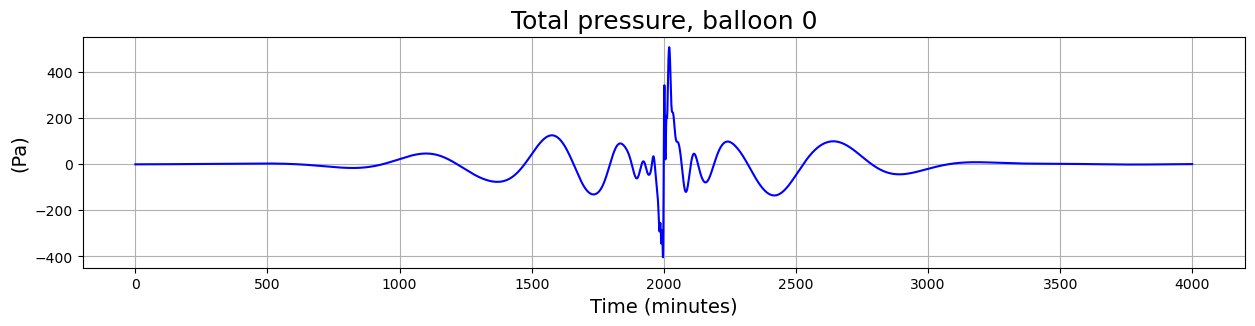

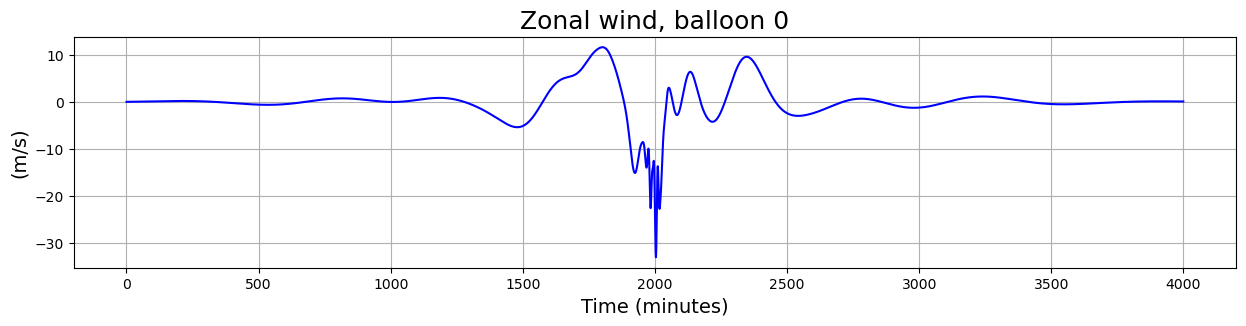

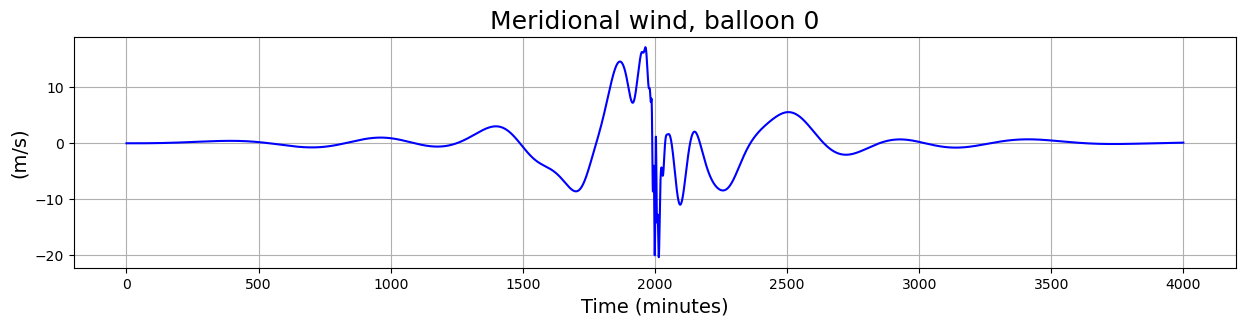

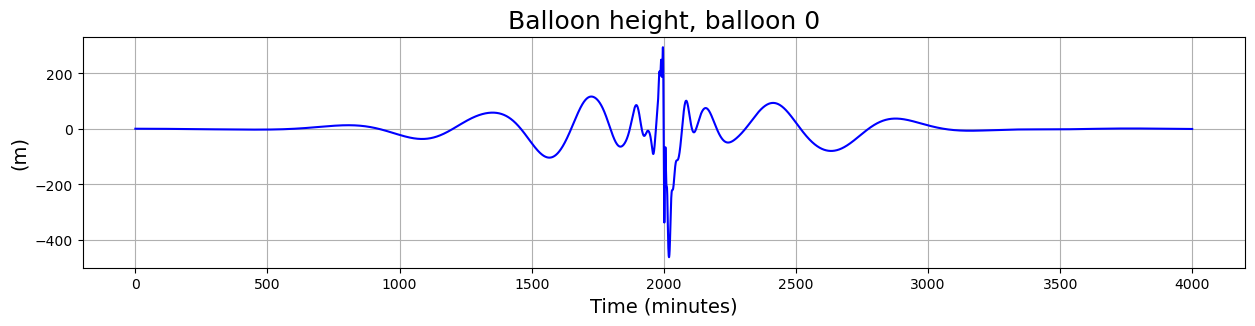

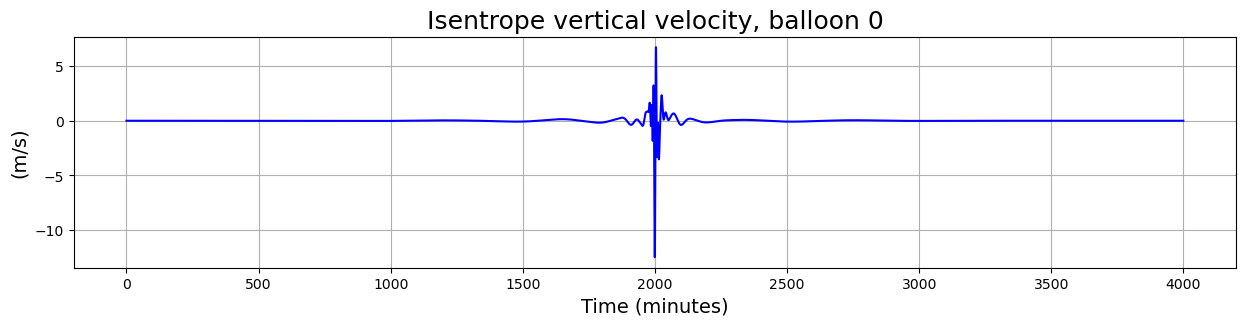

In [3]:
# Timeseries and packet properties
u = np.nan*np.ones(shape=(N,n_packet_frequencies+1,n_balloons))
v = np.nan*np.ones(shape=(N,n_packet_frequencies+1,n_balloons))
w = np.zeros(shape=(N,n_packet_frequencies+1,n_balloons))
delta_b = np.nan*np.ones(shape=(N,n_packet_frequencies+1,n_balloons))
pt = np.nan*np.ones(shape=(N,n_packet_frequencies+1,n_balloons))
packet_omega = np.nan*np.ones(shape=(n_packet_frequencies,n_balloons))
total_flux_packets = np.nan*np.ones(shape=(n_packet_frequencies,n_balloons))
Ekh_packets = np.nan*np.ones(shape=(n_packet_frequencies,n_balloons))
Ekv_packets = np.nan*np.ones(shape=(n_packet_frequencies,n_balloons))
Ep_packets = np.nan*np.ones(shape=(n_packet_frequencies,n_balloons))

# The frequency range of each packet and the horizontal angle (the values will be filled in after
# omega, theta_horiz are defined)
packet_theta_horiz = np.nan*np.ones(shape = (n_packet_frequencies, n_balloons))
packet_frequency_edges = np.nan*np.ones(shape = (n_packet_frequencies + 1, n_balloons))
packet_frequency_edges[0,:] = np.abs(f)
packet_frequency_edges[-1,:] = Nref


for j in np.arange(n_balloons):
    
    # Steps 1, 2, and 3 of Vincent and Hertzog (2014; "VH14"); the packet frequency, phase speed, and wavenumbers
    # Packet fraquency:
    omega = 10**(np.log10(np.abs(f)) + np.log10((Nref)/np.abs(f))*
                 np.random.uniform(low=0.0, high=1.0, size=n_packet_frequencies))
    omega = np.sort(omega)
    packet_omega[:,j] = omega
    packet_frequency_edges[1:-1,j] = 0.5*(omega[1:] + omega[:-1])
    # Packet phase speed:
    c = np.random.uniform(low=packet_c_low, high=packet_c_high, size=n_packet_frequencies)
    c = np.abs(c)
    # Packet horizontal orientation:
    if packet_theta_horiz_type == 1:
        theta_horiz = packet_theta_horiz_mean*np.ones(n_packet_frequencies)
    elif packet_theta_horiz_type == 2:
        theta_horiz = np.random.uniform(low=-np.pi, high=np.pi, size=n_packet_frequencies)
    packet_theta_horiz[:,j] = theta_horiz
    # The wavenumbers are derived:
    kh = omega/c
    k = kh*np.cos(theta_horiz)
    l = kh*np.sin(theta_horiz)
    #m = -np.sqrt(((Nref**2 - omega**2)/(omega**2 - f**2))*kh**2 - 1/(4*H**2)) # Eq. 24 of FA03
    m = -np.sqrt(((Nref**2 - omega**2)/(omega**2 - f**2))*kh**2) # Eq. 24 of FA03; Boussinesq
    if packet_m_sign == 2:
        temp = np.random.randint(low=0, high=2, size=n_packet_frequencies)
        temp[temp == 0] = -1
        m = m*temp

    # Step 4: the complex wave amplitudes, from the polarization relations in Fritts and Alexander 2003, 2012
    mag_up = np.random.uniform(low=mag_up_low, high=mag_up_high, size=n_packet_frequencies)
    # The magnitudes of u and v come from projecting mag_up onto the vector (k,l) of unit length,
    # then using the polarization relation Eq. 26 of Fritts and Alexander (2003) to isolate u or v.
    mag_u = mag_up*(omega*k + 1j*f*l)/(omega*np.sqrt(k**2 + l**2))
    mag_v = mag_up*(omega*l - 1j*f*k)/(omega*np.sqrt(k**2 + l**2))
    mag_p = rho_bar*mag_u*(omega**2 - f**2)/(omega*k + 1j*f*l) # Eq. 27 of FA03
    #mag_w = -mag_up*((omega**2 - f**2)/(Nref**2 - omega**2))*(m + 1j/(2*H))/kh  # Eq. 25 of VH14
    mag_w = -mag_up*((omega**2 - f**2)/(Nref**2 - omega**2))*(m/kh)  # Eq. 25 of VH14; Boussinesq

    # Step 5: wave and balloon vertical displacements
    mag_delta = 1j*mag_w/omega
    mag_delta_b = mag_delta*Z_EDS

    # Step 6: the total pressure perturbation (what the balloon measures)
    mag_pt = mag_p + dpdz_bar*mag_delta_b # Eq. 16 of VH14

    # Make the time series
    for i in np.arange(n_packet_frequencies):
        
        # Gravity wave packet width (in time)
        packet_width_temp = packet_width*2*np.pi/(60*omega[i])
        
        # Make the sinusoids
        phase_offset = np.random.uniform(low=-np.pi, high=np.pi, size=1) # randomize the phase of the wave
        #phase_offset = 0
        temp_omega = 60*omega[i] # convert omega from seconds**-1 to minutes**-1
        pt_temp = np.real(mag_pt[i]*np.exp(-1j*(temp_omega*t + phase_offset)))
        u_temp = np.real(mag_u[i]*np.exp(-1j*(temp_omega*t + phase_offset)))
        v_temp = np.real(mag_v[i]*np.exp(-1j*(temp_omega*t + phase_offset)))
        delta_b_temp = np.real(mag_delta_b[i]*np.exp(-1j*(temp_omega*t + phase_offset)))
        w_temp = np.zeros(N)
        w_temp[1:-1] = 0.5*(delta_b_temp[2:] - delta_b_temp[:-2])/(60*dt*Z_EDS)
            
        # Locate the packets in the middle of the time series
        packet_loc = (N*dt/2)
            
        # Apply the packet envelope
        envelope = np.exp(-(t-packet_loc)**2/(2*packet_width_temp**2))
        pt_temp = pt_temp*envelope
        u_temp = u_temp*envelope
        v_temp = v_temp*envelope
        delta_b_temp = delta_b_temp*envelope
        w_temp = w_temp*envelope
            
        # Get the momentum flux and energy for each packet
        uwbar_packets = np.nanmean(u_temp*w_temp)
        vwbar_packets = np.nanmean(v_temp*w_temp)
        total_flux_packets[i,j] = np.sqrt(uwbar_packets**2 + vwbar_packets**2)
        Ekh_packets[i,j] = 0.5*np.nanmean(u_temp**2 + v_temp**2)
        Ekv_packets[i,j] = 0.5*np.nanmean(w_temp**2)
        Ep_packets[i,j] = (0.5*Nref**2)*np.nanmean((delta_b_temp/Z_EDS)**2)
        
        # Save the timeseries
        u[:,i,j] = u_temp
        v[:,i,j] = v_temp
        delta_b[:,i,j] = delta_b_temp
        pt[:,i,j] = pt_temp
        w[:,i,j] = w_temp

# Combine the packets into one time series for each balloon
u[:,-1,:] = np.nansum(u[:,:-1,:],axis=1)
v[:,-1,:] = np.nansum(v[:,:-1,:],axis=1)
delta_b[:,-1,:] = np.nansum(delta_b[:,:-1,:],axis=1)
pt[:,-1,:] = np.nansum(pt[:,:-1,:],axis=1)
w[:,-1,:] = np.nansum(w[:,:-1,:],axis=1)
total_energy_packets = Ekh_packets + Ekv_packets + Ep_packets

# Scale the balloon displacement by 1/Z_EDS to get the isentrope displacement
delta_theta = delta_b/Z_EDS

# Plot one of the balloons' time series
balloon_to_plot = 0

plt.figure(figsize=(15,3))
plt.plot(t,pt[:,-1,balloon_to_plot],'b')
plt.grid()
plt.title(f'Total pressure, balloon {balloon_to_plot}', fontsize=18)
plt.xlabel('Time (minutes)', fontsize=14)
plt.ylabel('(Pa)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t,u[:,-1,balloon_to_plot],'b')
plt.grid()
plt.title(f'Zonal wind, balloon {balloon_to_plot}', fontsize=18)
plt.xlabel('Time (minutes)', fontsize=14)
plt.ylabel('(m/s)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t,v[:,-1,balloon_to_plot],'b')
plt.grid()
plt.title(f'Meridional wind, balloon {balloon_to_plot}', fontsize=18)
plt.xlabel('Time (minutes)', fontsize=14)
plt.ylabel('(m/s)', fontsize=14);

plt.figure(figsize=(15,3))
plt.plot(t,delta_b[:,-1,balloon_to_plot],'b')
plt.grid()
plt.title(f'Balloon height, balloon {balloon_to_plot}', fontsize=18)
plt.xlabel('Time (minutes)', fontsize=14)
plt.ylabel('(m)', fontsize=14);
#plt.savefig('../plots/temp1.pdf', format='pdf', bbox_inches='tight');

plt.figure(figsize=(15,3))
plt.plot(t,w[:,-1,balloon_to_plot],'b')
plt.grid()
plt.title(f'Isentrope vertical velocity, balloon {balloon_to_plot}', fontsize=18)
plt.xlabel('Time (minutes)', fontsize=14)
plt.ylabel('(m/s)', fontsize=14);

### Wavelet analysis function

In [4]:
## WAVELET ANALYSIS
# All equation and table numbers are from Torrence and Compo (1998)

# Create a dataclass for the variables returned from the analysis
@dataclass
class ReturnValue:
    N_pad: float;
    #X_recon: float;
    wave: float;
    #wave_power: float;
    #total_power: float;
    #global_power: float;
    global_power_rescaling: float;
    #total_global_power: float;
    C_delta: float;
    s: float;
    frequency: float;
    period: float;
    coi: float;
    #fftfreq: float;
    #fft: float;
    #fft_power: float;
    #fft_total_power: float;
    #fft_power_rescaling: float;
                    
# The input time series must have a mean of zero
def run_Morlet_CWT(X,dt,omega0,dj):
        
    N = np.size(X)
    std = np.std(X)
    var = std**2

    # Add zero padding and normalize to unit variance
    # The length of the new time series is 2*N for N even, 2*N + 1 for N odd
    N_pad = int(np.ceil(N/2))
    X_norm = np.zeros(N + 2*N_pad)
    X_norm[N_pad:N+N_pad] = X
    X_norm = X_norm/np.std(X_norm)
    N = N + 2*N_pad
    
    # Take the FFT of X_norm and make the frequencies (Eq. 5)
    X_norm_fft = np.fft.fft(X_norm)

    # Calculate the scales and Fourier equivalent frequencies and periods
    s0 = 2*dt*(omega0 + np.sqrt(2 + omega0**2))/(4*np.pi) # An inversion of Table 1 so the shortest period is 2*dt
    J = (1/dj)*np.log2(N*dt/s0) # (Eq. 10)
    J = int(np.ceil(J))
    s = s0*2**(dj*np.arange(J+1)) # (Eq. 9)
    s_tiled = np.tile(s,(N,1)).swapaxes(0,1)
    period = 4*np.pi*s/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    frequency = 1/period
    nscales = s.size
    
    # Loop through the scales to calculate the wavelet transform
    omega = 2*np.pi*np.fft.fftfreq(N)/dt # (Eq. 5) np.fft.fftfreq outputs (0,1,2,...)/N
    wave = np.nan*(1+1j)*np.ones(shape=(nscales,N))
    wave_delta = np.nan*np.ones(nscales)
    for i in np.arange(nscales):
        
        # Calculate the wavelet function (np.heaviside(0,0) = 0, so psi_hat(0) = 0 and the 
        # wavelet is admissible by construction (Section 3.3 of Farge 1992))
        psi_hat_0 = (np.pi**-0.25)*np.heaviside(omega,0)*np.exp(-0.5*(s[i]*omega - omega0)**2) # (Table 1)
        psi_hat = np.sqrt(2*np.pi*s[i]/dt)*psi_hat_0 # (Eq. 6) 
        
        # Calculate the wavelet transform
        wave[i,:] = np.fft.ifft(X_norm_fft*np.conj(psi_hat)) # (Eq. 4)
    
    # Estimate the reconstruction factor C_delta
    # Force the wavelet power spectrogram to have unit variance:
    C_delta = (dj*dt/N)*np.sum(np.abs(wave**2)/s_tiled) # (Eq. 14)
    
    ## Reconstruct the input time series
    #psi_0_0 = np.pi**-0.25 # (Table 2)
    #X_norm_recon = (dj*np.sqrt(dt)/(C_delta*psi_0_0))*np.sum(np.real(wave)/np.sqrt(s_tiled),axis=0) # (Eq. 11)
    
    ## Calculate dimensional quantities
    #N = N - 2*N_pad # N now matches the input time series length again
    ## The scaling is chosen so that the values are correct after the zero padding is removed
    #var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    #wave_power = (var/var_ratio)*np.abs(wave)**2
    #global_power = (1/N)*np.sum(wave_power, axis=1) # (Eq. 2)
    #total_power = (dj*dt/C_delta)*np.sum(wave_power/s_tiled, axis=0) # (Eq. 24)
    #total_global_power = (dj*dt/C_delta)*np.sum(global_power/s) # (Eq. 14)
    #global_total_power = (1/N)*np.sum(total_power)
    #X_recon = np.sqrt(var/var_ratio)*X_norm_recon # This (almost) equals the input time series + zero padding
    
    # Define a scaling so that the integral of the global power times the frequency
    # over the natural logarithm of the frequency equals the total variance. This helps
    # when plotting and comparing the global power spectrum to the FFT power spectrum.
    # Combining Eq. 9, Eq. 14, and Table 1:
    global_power_rescaling = (dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    
    # Calculate the COI (outputs the period versus time)
    coi = dt*np.arange(N)*(2**-0.5) # TC98 table 1
    coi = 4*np.pi*coi/(omega0 + np.sqrt(2 + omega0**2)) # (Table 1) wavelet equivalent FFT period
    coi = np.minimum(coi, np.flipud(coi))
    
    ## FFT analysis
    #ind_switchfreq_fft = 1 + int(np.floor(N/2))
    #fft = np.fft.fft(X/std)
    #fftfreq = np.fft.fftfreq(N,dt)
    #fft = fft[:ind_switchfreq_fft] # turn into a one-sided spectrum
    #fftfreq = np.abs(fftfreq[:ind_switchfreq_fft]) # turn into a one-sided spectrum
    #fft_power = (2*var/N)*np.abs(fft)**2 # dimensional power spectra 
    #fft_power[0] = fft_power[0]/2 # don't double-count the zero-frequency power
    #fft_total_power = (1/N)*np.sum(fft_power)
    #fft_power_rescaling = dt # a rescaling of fft_power so the integral over frequency = variance
        
    return ReturnValue(N_pad,
                       #X_recon,
                       wave,
                       #wave_power,
                       #total_power,
                       #global_power,
                       global_power_rescaling,
                       #total_global_power,
                       C_delta,
                       s,
                       frequency,
                       period,
                       coi)
                       #fftfreq,
                       #fft,
                       #fft_power,
                       #fft_total_power,
                       #fft_power_rescaling)

### The code for analyzing each set of timeseries

In [5]:
# Create a dataclass for the variables returned from the analysis
@dataclass
class ReturnValueFluxes:
    frequency: float;
    flux_spectrum: float;
    Etotal_scaled_spectrum: float;
    flux_spectrum_upw: float;
    flux_spectrum_uppt: float;
    Etotal_spectrum: float;
    Ekh_spectrum: float;
    Ekv_spectrum: float;
    Ep_spectrum: float;
    flux_total: float;
    Etotal_scaled_total: float;
    flux_total_upw: float;
    flux_total_uppt: float;
    rescaled_upw: float;
    Etotal_total: float;
    Ekh_total: float;
    Ekv_total: float;
    Ep_total: float;
    flux_spectrum_absupw: float;
    flux_spectrum_absuppt: float;
    rescaled_uppt: float;
    flux_total_absupw: float;
    flux_total_absuppt: float;
    power_spectrum_up: float;
    total_power_up: float;
    zonal_flux_total: float;
    rescaled_uw: float;
    rescaled_vw: float;
    
                    
# The input time series must have a mean of zero
def analyze_segment(u,v,w,delta_theta,pt,rho_bar,H,Nref,packet_omega):
    
    N = np.size(t)

    # Normalize the time series
    std_w = np.std(w)
    std_u = np.std(u)
    std_v = np.std(v)
    std_delta_theta = np.std(delta_theta)
    std_pt = np.std(pt)
    var_w = std_w**2
    var_u = std_u**2
    var_v = std_v**2
    var_delta_theta = std_delta_theta**2
    var_pt = std_pt**2

    # Run the wavelet analysis
    w_output = run_Morlet_CWT(w,dt,omega0,dj)
    u_output = run_Morlet_CWT(u,dt,omega0,dj)
    v_output = run_Morlet_CWT(v,dt,omega0,dj)
    delta_theta_output = run_Morlet_CWT(delta_theta,dt,omega0,dj)
    pt_output = run_Morlet_CWT(pt,dt,omega0,dj)

    # Pull out a couple common variables to make some calculations easier
    period = u_output.period; frequency = u_output.frequency; scale = u_output.s
    N_pad = u_output.N_pad; coi = u_output.coi
    C_delta = 0.5*(u_output.C_delta + v_output.C_delta)
    nscales = np.size(scale)
    var_ratio = (N + 2*N_pad)/N # the reduction in variance due to the zero padding (= 2 for N even)
    scale_tiled_padded = np.tile(scale,(N + 2*N_pad,1)).swapaxes(0,1)
    
    # Calculate u_parallel (variable name: up)
    Ur = np.sqrt(var_u/var_ratio)*np.real(u_output.wave)
    Ui = np.sqrt(var_u/var_ratio)*np.imag(u_output.wave)
    Vr = np.sqrt(var_v/var_ratio)*np.real(v_output.wave)
    Vi = np.sqrt(var_v/var_ratio)*np.imag(v_output.wave)
    # Temporary variables
    A = Ur**2 + Vr**2
    B = Ui**2 + Vi**2
    C = Ur*Ui + Vr*Vi
    # For uh**2 = u**2 + v**2, solve the equation for theta for when d(uh)/d(theta) = 0.
    # This will give two answers, pi/2 apart: when uh is at a minimum (Ud) and when it is
    # at a maximum (Up). Theta is the phase shift relative to the current time step.
    guess_theta = np.ndarray(shape=(2,nscales,N + 2*N_pad))
    guess_theta[0,:,:] = 0.5*np.arctan2(2*C,(B-A))
    guess_theta[1,:,:] = guess_theta[0,:,:] + np.pi/2
    # Plug the phase into the equation for uh:
    A = np.tile(A,(2,1,1))
    B = np.tile(B,(2,1,1))
    C = np.tile(C,(2,1,1))
    guess_Up = np.sqrt(A*(np.cos(guess_theta))**2 + 
                       B*(np.sin(guess_theta))**2 - 
                       C*np.sin(2*guess_theta))
    # From the two angles, pi/2 apart, get u_parallel (Up) and u_perpendicular (Ud)
    Up = np.max(guess_Up, axis=0)
    # If up maximizes at the guess_theta angle that corresponds to Up, the phase of up
    # at the current time step is the negative of that angle.
    temp = np.tile(Up,(2,1,1)) - guess_Up
    theta_Up = -np.nansum(guess_theta*np.isnan(temp/temp), axis=0)
    # Set Up, Ud, and their angles to zero if nan
    Up[np.isnan(Up)==1] = 0
    theta_Up[np.isnan(theta_Up)==1] = 0
    # When up is at a maximum (-theta_Up), calculate the angle it makes clockwise from due East.
    Up_u = Ur*np.cos(-theta_Up) - Ui*np.sin(-theta_Up)
    Up_v = Vr*np.cos(-theta_Up) - Vi*np.sin(-theta_Up)
    del Ur, Ui, Vr, Vi
    theta_horiz_wave = np.arctan2(Up_v,Up_u)
    del Up_u, Up_v
    # There's a 180-degree ambiguity in the phases, giving the impression that up/d
    # sweep through only one-half period, with theta_horiz flipping 180 degrees
    # after each of these half-periods. Pick one side of zero for theta_horiz and shift the
    # phase of Up (theta_Up) by 180 degrees on that side.
    theta_Up[theta_horiz_wave<0] = theta_Up[theta_horiz_wave<0] - np.pi
    del theta_horiz_wave
    # Make sure theta_Up goes from -pi to pi
    theta_Up[theta_Up>np.pi] = theta_Up[theta_Up>np.pi] - 2*np.pi
    theta_Up[theta_Up<-np.pi] = theta_Up[theta_Up<-np.pi] + 2*np.pi
    # Calculate the real and imaginary components of up and ud.
    # For theta = 0 at the current time step, up = Up*cos(theta+theta_Up),
    # and up = UPr*cos(theta) - Upi*sin(theta), at theta = 0 or pi/2:
    Upr = Up*np.cos(theta_Up)
    Upi = Up*np.sin(theta_Up)
    del theta_Up
    # Calculate the total power of Up (the wavelet that I'm starting from is the 
    # dimensional amplitude, not the non-dimensional wavelet)
    Up_total_power = (dj*dt/C_delta)*np.sum(Up**2/scale_tiled_padded, axis=0)
    del Up
    # Normalize the up wavelet amplitudes
    var_up_recon = (1/N)*np.nansum(Up_total_power)
    std_up_recon = np.sqrt(var_up_recon)
    wave_up = (Upr + 1j*Upi)/np.sqrt(var_up_recon/var_ratio)
    del Upr, Upi
    
    # Calculate the cross-spectra of u, v and the vertical velocity
    crossspec_u_w_full = w_output.wave*np.conj(u_output.wave) # this is the normalized spectrum
    crossspec_v_w_full = w_output.wave*np.conj(v_output.wave) # this is the normalized spectrum
    crossspec_up_w_full = w_output.wave*np.conj(wave_up) # this is the normalized spectrum
    # Force the real part of the up-w cross-spectrum to be positive
    # and calculate the up-pt cross-spectrum
    wave_up[np.real(crossspec_up_w_full) < 0] = -wave_up[np.real(crossspec_up_w_full) < 0]
    crossspec_up_w_full = w_output.wave*np.conj(wave_up) # this is the normalized spectrum
    crossspec_up_pt_full = pt_output.wave*np.conj(wave_up) # this is the normalized spectrum
    # Force the imaginary part of the up-pt cross-spectrum to be positive
    temp = wave_up.copy()
    temp[np.imag(crossspec_up_pt_full) < 0] = -temp[np.imag(crossspec_up_pt_full) < 0]
    crossspec_up_pt_full = pt_output.wave*np.conj(temp) # this is the normalized spectrum
    del pt_output
    # Scale the up-pt cross-spectra so it has the dimensions of the momentum flux (VH14 Eq. 26)
    factor = np.tile(2*np.pi*frequency/60,(N + 2*N_pad, 1)).swapaxes(0,1) # (rad/sec)
    factor = factor/(rho_bar*H*Nref**2) # VH14 Eq. 26
    crossspec_up_pt_full = factor*crossspec_up_pt_full
    
    # Calculate C_delta so that the cross-spectral power is conserved, using the full
    # u-w and v-w cross-spectra
    uw_bar = np.nanmean(u*w)
    vw_bar = np.nanmean(v*w)
    temp = (std_u*std_w/var_ratio)*(dj*dt)* \
           np.sum(np.real(crossspec_u_w_full)/scale_tiled_padded, axis=0)
    C_delta_uw = (1/N)*np.sum(temp)/uw_bar
    temp = (std_v*std_w/var_ratio)*(dj*dt)* \
           np.sum(np.real(crossspec_v_w_full)/scale_tiled_padded, axis=0)
    C_delta_vw = (1/N)*np.sum(temp)/vw_bar
    del scale_tiled_padded
    
    # Calculate the kinetic energy from the zero-padded wavelet output
    wave_Ekh = (0.5/var_ratio)*(var_u*u_output.global_power_rescaling*np.abs(u_output.wave)**2 + 
                                var_v*v_output.global_power_rescaling*np.abs(v_output.wave)**2)
    wave_Ekv = (0.5/var_ratio)*(var_w*w_output.global_power_rescaling*np.abs(w_output.wave)**2)

    # Calculate the potential energy from the zero-padded wavelet output
    wave_Ep = 0.5*(Nref**2)*(var_delta_theta/var_ratio)*delta_theta_output.global_power_rescaling* \
              np.abs(delta_theta_output.wave)**2 # Eq. 2, Podglajen et al 2016
    
    del u_output, v_output, w_output, delta_theta_output
    
    # Calculate the spectra of the total momentum and pseudomomentum fluxes,
    # and rescale the spectra so that the total fluxes are equal to the
    # integrals of the spectra times frequency over dlog(frequency)
    # First, calculate the rescaling factor and apply it to the (signed) cross-spectra:
    temp = (std_u*std_w/var_ratio)*crossspec_u_w_full
    temp_rescaling = (dt/C_delta_uw)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    rescaled_uw = temp*temp_rescaling
    del crossspec_u_w_full
    temp = (std_v*std_w/var_ratio)*crossspec_v_w_full
    temp_rescaling = (dt/C_delta_vw)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    rescaled_vw = temp*temp_rescaling
    del crossspec_v_w_full
    temp = (std_up_recon*std_w/var_ratio)*crossspec_up_w_full
    temp_rescaling = (dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    rescaled_upw = temp*temp_rescaling
    del crossspec_up_w_full
    temp = (std_up_recon*std_pt/var_ratio)*crossspec_up_pt_full
    temp_rescaling = (dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    rescaled_uppt = temp*temp_rescaling
    del crossspec_up_pt_full
    temp = ((std_up_recon**2)/var_ratio)*np.abs(wave_up)**2
    temp_rescaling = (dt/C_delta)*4*np.pi*np.log2(np.exp(1))/(omega0+np.sqrt(2+omega0**2))
    rescaled_up_power = temp*temp_rescaling
    del wave_up
    # Then take the absolute values of the rescaled spectra, square them, and take
    # the square root of their sum
    wave_total_flux = np.sqrt(np.abs(np.real(rescaled_uw))**2 + np.abs(np.real(rescaled_vw))**2)
    wave_zonal_flux = np.real(rescaled_uw)
    #del rescaled_uw, rescaled_vw
    # Global spectra
    global_total_flux = (1/N)*np.sum(wave_total_flux, axis=1)
    global_total_flux_upw = (1/N)*np.sum(np.real(rescaled_upw), axis=1)
    global_total_flux_absupw = (1/N)*np.sum(np.abs(rescaled_upw), axis=1)
    global_total_flux_uppt = (1/N)*np.sum(np.imag(rescaled_uppt), axis=1)
    global_total_flux_absuppt = (1/N)*np.sum(np.abs(rescaled_uppt), axis=1)
    global_power_up = (1/N)*np.sum(np.abs(rescaled_up_power), axis=1)
    global_zonal_flux = (1/N)*np.sum(wave_zonal_flux, axis=1)
    del wave_total_flux, rescaled_up_power, wave_zonal_flux

    # Global energy spectra
    wave_Etotal = wave_Ekh + wave_Ekv + wave_Ep
    global_Etotal = (1/N)*np.sum(wave_Etotal, axis=1)
    global_Ekh = (1/N)*np.sum(wave_Ekh, axis=1)
    global_Ekv = (1/N)*np.sum(wave_Ekv, axis=1)
    global_Ep = (1/N)*np.sum(wave_Ep, axis=1)
    del wave_Ekh, wave_Ekv, wave_Ep
    # Re-scale the total energy to be comparable to the u-w cross-spectrum
    # Calculate the scaling factor
    frequency_rad = 2*np.pi*frequency/60 # (rad/s)
    frequency_rad = np.tile(frequency_rad,(N+2*N_pad,1)).swapaxes(0,1)
    factor = (frequency_rad**2 - f**2)/(Nref**2 - f**2)
    factor = factor*(Nref**2 - frequency_rad**2)/(Nref**2 - f**2)
    factor = np.sqrt(factor)
    wave_Etotal_scaled = factor*wave_Etotal
    global_Etotal_scaled = (1/N)*np.sum(wave_Etotal_scaled, axis=1)
    del wave_Etotal, wave_Etotal_scaled, frequency_rad, factor

    # For integration, delete coefficients outside the GW frequency range
    temp_Etotal_scaled = global_Etotal_scaled.copy()
    temp_flux = global_total_flux.copy()
    temp_upw = global_total_flux_upw.copy()
    temp_uppt = global_total_flux_uppt.copy()
    temp_absupw = global_total_flux_absupw.copy()
    temp_absuppt = global_total_flux_absuppt.copy()
    temp_Etotal = global_Etotal.copy()
    temp_Ekh = global_Ekh.copy()
    temp_Ekv = global_Ekv.copy()
    temp_Ep = global_Ep.copy()
    temp_up = global_power_up.copy()
    temp_zonal_flux = global_zonal_flux.copy()
    # Eliminate coefficients with periods shorter than either the buoyancy period or GW_PERIOD_MIN
    period_N = 2*np.pi/(60*Nref) # the buoyancy period
    min_period = period_N
    temp = min_period - period
    temp_Etotal_scaled[temp >= 0] = 0
    temp_flux[temp >= 0] = 0
    temp_upw[temp >= 0] = 0
    temp_uppt[temp >= 0] = 0
    temp_absupw[temp >= 0] = 0
    temp_absuppt[temp >= 0] = 0
    temp_Etotal[temp >= 0] = 0
    temp_Ekh[temp >= 0] = 0
    temp_Ekv[temp >= 0] = 0
    temp_Ep[temp >= 0] = 0
    temp_up[temp >= 0] = 0
    temp_zonal_flux[temp >= 0] = 0
    # Eliminate coefficients at periods too close to either the Coriolis period or GW_PERIOD_MAX
    period_f = np.abs(2*np.pi/(60*f))
    max_period = period_f
    temp = max_period - period
    temp_Etotal_scaled[temp < 0] = 0
    temp_flux[temp < 0] = 0
    temp_upw[temp < 0] = 0
    temp_uppt[temp < 0] = 0
    temp_absupw[temp < 0] = 0
    temp_absuppt[temp < 0] = 0
    temp_Etotal[temp < 0] = 0
    temp_Ekh[temp < 0] = 0
    temp_Ekv[temp < 0] = 0
    temp_Ep[temp < 0] = 0
    temp_up[temp < 0] = 0
    temp_zonal_flux[temp < 0] = 0

    # Integrate
    Etotal_scaled_total = dj*np.log(2)*np.nansum(temp_Etotal_scaled*frequency)
    total_flux_total = dj*np.log(2)*np.nansum(temp_flux*frequency)
    total_flux_upw_total = dj*np.log(2)*np.nansum(temp_upw*frequency)
    total_flux_uppt_total = dj*np.log(2)*np.nansum(temp_uppt*frequency)
    total_flux_absupw_total = dj*np.log(2)*np.nansum(temp_absupw*frequency)
    total_flux_absuppt_total = dj*np.log(2)*np.nansum(temp_absuppt*frequency)
    Etotal_total = dj*np.log(2)*np.nansum(temp_Etotal*frequency)
    Ekh_total = dj*np.log(2)*np.nansum(temp_Ekh*frequency)
    Ekv_total = dj*np.log(2)*np.nansum(temp_Ekv*frequency)
    Ep_total = dj*np.log(2)*np.nansum(temp_Ep*frequency)
    total_power_up = dj*np.log(2)*np.nansum(temp_up*frequency)
    zonal_flux_total = dj*np.log(2)*np.nansum(temp_zonal_flux*frequency)
    
    # Organize the output
    frequency = frequency
    flux_spectrum = global_total_flux
    Etotal_scaled_spectrum = global_Etotal_scaled
    flux_spectrum_upw = global_total_flux_upw
    flux_spectrum_uppt = global_total_flux_uppt
    Etotal_spectrum = global_Etotal
    Ekh_spectrum = global_Ekh
    Ekv_spectrum = global_Ekv
    Ep_spectrum = global_Ep
    flux_total = total_flux_total
    Etotal_scaled_total = Etotal_scaled_total
    flux_total_upw = total_flux_upw_total
    flux_total_uppt = total_flux_uppt_total
    rescaled_upw = rescaled_upw
    Etotal_total = Etotal_total
    Ekh_total = Ekh_total
    Ekv_total = Ekv_total
    Ep_total = Ep_total
    flux_spectrum_absupw = global_total_flux_absupw
    flux_spectrum_absuppt = global_total_flux_absuppt
    rescaled_uppt = rescaled_uppt
    flux_total_absupw = total_flux_absupw_total
    flux_total_absuppt = total_flux_absuppt_total
    power_spectrum_up = global_power_up
    total_power_up = total_power_up
    zonal_flux_total = zonal_flux_total
    rescaled_uw = rescaled_uw
    rescaled_vw = rescaled_vw
    
    return ReturnValueFluxes(frequency,
                             flux_spectrum,
                             Etotal_scaled_spectrum,
                             flux_spectrum_upw,
                             flux_spectrum_uppt,
                             Etotal_spectrum,
                             Ekh_spectrum,
                             Ekv_spectrum,
                             Ep_spectrum,
                             flux_total,
                             Etotal_scaled_total,
                             flux_total_upw,
                             flux_total_uppt,
                             rescaled_upw,
                             Etotal_total,
                             Ekh_total,
                             Ekv_total,
                             Ep_total,
                             flux_spectrum_absupw,
                             flux_spectrum_absuppt,
                             rescaled_uppt,
                             flux_total_absupw,
                             flux_total_absuppt,
                             power_spectrum_up,
                             total_power_up,
                             zonal_flux_total,
                             rescaled_uw,
                             rescaled_vw)

### The code for executing the analysis and collecting and analyzing the output

In [6]:
# To get the number of frequencies:
N_pad = int(np.ceil(N/2))
N_temp = N + 2*N_pad
s0 = 2*dt*(omega0 + np.sqrt(2 + omega0**2))/(4*np.pi) # An inversion of Table 1 so the shortest period is 2*dt
J = (1/dj)*np.log2(N_temp*dt/s0) # (Eq. 10)
nscales = 1 + int(np.ceil(J))

flux_spectrum = np.nan*np.ones(shape=(nscales,n_balloons))
flux_spectrum_eachpacket = np.nan*np.ones(shape=(nscales,n_balloons,n_packet_frequencies+1))
Etotal_scaled_spectrum = np.nan*np.ones(shape=(nscales,n_balloons))
flux_spectrum_upw = np.nan*np.ones(shape=(nscales,n_balloons))
flux_spectrum_uppt = np.nan*np.ones(shape=(nscales,n_balloons))
flux_spectrum_absupw = np.nan*np.ones(shape=(nscales,n_balloons))
flux_spectrum_absuppt = np.nan*np.ones(shape=(nscales,n_balloons))
flux_spectrum_upw_eachpacket = np.nan*np.ones(shape=(nscales,n_balloons))
flux_spectrum_absupw_eachpacket = np.nan*np.ones(shape=(nscales,n_balloons))
flux_spectrum_upw_correct_dtheta = np.nan*np.ones(shape=(nscales,n_balloons))
flux_spectrum_upw_correct_UpW = np.nan*np.ones(shape=(nscales,n_balloons))
flux_spectrum_uppt_eachpacket = np.nan*np.ones(shape=(nscales,n_balloons))
flux_spectrum_absuppt_eachpacket = np.nan*np.ones(shape=(nscales,n_balloons))
flux_spectrum_uppt_correct_dtheta = np.nan*np.ones(shape=(nscales,n_balloons))
flux_spectrum_uppt_correct_UpPT = np.nan*np.ones(shape=(nscales,n_balloons))
Etotal_spectrum = np.nan*np.ones(shape=(nscales,n_balloons,n_packet_frequencies+1))
Ekh_spectrum = np.nan*np.ones(shape=(nscales,n_balloons,n_packet_frequencies+1))
Ekv_spectrum = np.nan*np.ones(shape=(nscales,n_balloons,n_packet_frequencies+1))
Ep_spectrum = np.nan*np.ones(shape=(nscales,n_balloons,n_packet_frequencies+1))
flux_total = np.nan*np.ones(n_balloons)
flux_total_eachpacket = np.nan*np.ones(shape=(n_balloons,n_packet_frequencies+1))
Etotal_scaled_total = np.nan*np.ones(n_balloons)
flux_total_upw = np.nan*np.ones(n_balloons)
flux_total_uppt = np.nan*np.ones(n_balloons)
flux_total_absupw = np.nan*np.ones(n_balloons)
flux_total_absuppt = np.nan*np.ones(n_balloons)
flux_total_upw_eachpacket = np.nan*np.ones(n_balloons)
flux_total_absupw_eachpacket = np.nan*np.ones(n_balloons)
flux_total_upw_correct_dtheta = np.nan*np.ones(n_balloons)
flux_total_upw_correct_UpW = np.nan*np.ones(n_balloons)
flux_total_uppt_eachpacket = np.nan*np.ones(n_balloons)
flux_total_absuppt_eachpacket = np.nan*np.ones(n_balloons)
flux_total_uppt_correct_dtheta = np.nan*np.ones(n_balloons)
flux_total_uppt_correct_UpPT = np.nan*np.ones(n_balloons)
Etotal_total = np.nan*np.ones(shape=(n_balloons,n_packet_frequencies+1))
Ekh_total = np.nan*np.ones(shape=(n_balloons,n_packet_frequencies+1))
Ekv_total = np.nan*np.ones(shape=(n_balloons,n_packet_frequencies+1))
Ep_total = np.nan*np.ones(shape=(n_balloons,n_packet_frequencies+1))
spectrum_UpW_combined = np.nan*np.ones(shape=(nscales,n_balloons))
spectrum_UpW_eachpacket = np.nan*np.ones(shape=(nscales,n_balloons))
spectrum_UpPT_combined = np.nan*np.ones(shape=(nscales,n_balloons))
spectrum_UpPT_eachpacket = np.nan*np.ones(shape=(nscales,n_balloons))
up_power_spectrum = np.nan*np.ones(shape=(nscales,n_balloons,n_packet_frequencies+1))
up_power_total = np.nan*np.ones(shape=(n_balloons,n_packet_frequencies+1))
zonal_flux_total_eachpacket = np.nan*np.ones(shape=(n_balloons,n_packet_frequencies+1))
flux_spectrum_overlapping = np.nan*np.ones(shape=(nscales,n_balloons))
flux_total_overlapping = np.nan*np.ones(n_balloons)
#output_theta_horiz = np.nan*np.ones(shape=(n_balloons,n_packet_frequencies))

for i in np.arange(n_balloons):
    
    print(i+1, n_balloons)
    rescaled_upw = np.nan*(1+1j)*np.ones(shape=(nscales,N+2*N_pad,n_packet_frequencies+1))
    rescaled_uppt = np.nan*(1+1j)*np.ones(shape=(nscales,N+2*N_pad,n_packet_frequencies+1))
    rescaled_uw = np.nan*(1+1j)*np.ones(shape=(nscales,N+2*N_pad,n_packet_frequencies))
    rescaled_vw = np.nan*(1+1j)*np.ones(shape=(nscales,N+2*N_pad,n_packet_frequencies))
    
    # Do the analysis on each packet
    for j in np.arange(n_packet_frequencies):
        temp_output = analyze_segment(u[:,j,i],v[:,j,i],w[:,j,i],delta_theta[:,j,i],pt[:,j,i],rho_bar,H,Nref,packet_omega[j,i])
        flux_spectrum_eachpacket[:,i,j] = temp_output.flux_spectrum
        rescaled_upw[:,:,j] = temp_output.rescaled_upw
        rescaled_uppt[:,:,j] = temp_output.rescaled_uppt
        Etotal_spectrum[:,i,j] = temp_output.Etotal_spectrum
        Ekh_spectrum[:,i,j] = temp_output.Ekh_spectrum
        Ekv_spectrum[:,i,j] = temp_output.Ekv_spectrum
        Ep_spectrum[:,i,j] = temp_output.Ep_spectrum
        flux_total_eachpacket[i,j] = temp_output.flux_total
        Etotal_total[i,j] = temp_output.Etotal_total
        Ekh_total[i,j] = temp_output.Ekh_total
        Ekv_total[i,j] = temp_output.Ekv_total
        Ep_total[i,j] = temp_output.Ep_total
        up_power_spectrum[:,i,j] = temp_output.power_spectrum_up
        up_power_total[i,j] = temp_output.total_power_up
        zonal_flux_total_eachpacket[i,j] = temp_output.zonal_flux_total
        rescaled_uw[:,:,j] = temp_output.rescaled_uw
        rescaled_vw[:,:,j] = temp_output.rescaled_vw
        
    # Do the analysis on the combined timeseries
    temp_output = analyze_segment(u[:,-1,i],v[:,-1,i],w[:,-1,i],delta_theta[:,-1,i],pt[:,-1,i],rho_bar,H,Nref,2*Nref)
    frequency = temp_output.frequency
    flux_spectrum[:,i] = temp_output.flux_spectrum
    flux_spectrum_eachpacket[:,i,-1] = temp_output.flux_spectrum
    Etotal_scaled_spectrum[:,i] = temp_output.Etotal_scaled_spectrum
    flux_spectrum_upw[:,i] = temp_output.flux_spectrum_upw
    flux_spectrum_uppt[:,i] = temp_output.flux_spectrum_uppt
    flux_spectrum_absupw[:,i] = temp_output.flux_spectrum_absupw
    flux_spectrum_absuppt[:,i] = temp_output.flux_spectrum_absuppt
    flux_total[i] = temp_output.flux_total
    Etotal_scaled_total[i] = temp_output.Etotal_scaled_total
    flux_total_upw[i] = temp_output.flux_total_upw
    flux_total_uppt[i] = temp_output.flux_total_uppt
    flux_total_absupw[i] = temp_output.flux_total_absupw
    flux_total_absuppt[i] = temp_output.flux_total_absuppt
    rescaled_upw[:,:,-1] = temp_output.rescaled_upw
    Etotal_spectrum[:,i,-1] = temp_output.Etotal_spectrum
    Ekh_spectrum[:,i,-1] = temp_output.Ekh_spectrum
    Ekv_spectrum[:,i,-1] = temp_output.Ekv_spectrum
    Ep_spectrum[:,i,-1] = temp_output.Ep_spectrum
    flux_total_eachpacket[i,-1] = temp_output.flux_total
    Etotal_total[i,-1] = temp_output.Etotal_total
    Ekh_total[i,-1] = temp_output.Ekh_total
    Ekv_total[i,-1] = temp_output.Ekv_total
    Ep_total[i,-1] = temp_output.Ep_total
    rescaled_uppt[:,:,-1] = temp_output.rescaled_uppt
    up_power_spectrum[:,i,-1] = temp_output.power_spectrum_up
    up_power_total[i,-1] = temp_output.total_power_up
    zonal_flux_total_eachpacket[i,-1] = temp_output.zonal_flux_total
    
    # Calculate the total flux wavelet from the overlapping uw, vw cross-spectra
    rescaled_uw = np.nansum(np.real(rescaled_uw), axis=2)
    rescaled_vw = np.nansum(np.real(rescaled_vw), axis=2)
    rescaled_total = np.sqrt(rescaled_uw**2 + rescaled_vw**2)
    flux_spectrum_overlapping[:,i] = (1/N)*np.sum(rescaled_total, axis=1)
        
    # Do the bookkeeping for the error in the up-w cross spectrum due to the superposition of
    # GW wave packets. The notation is: Re(w*conj(up)) = UpW*cos(dtheta), where dtheta is
    # the phase difference between up and w, and UpW is mag(up)*mag(w)
    dtheta_combined = (180/np.pi)*np.arctan2(np.imag(rescaled_upw[:,:,-1]),
                                             np.real(rescaled_upw[:,:,-1]))
    dtheta_eachpacket = (180/np.pi)*np.arctan2(np.nansum(np.imag(rescaled_upw[:,:,:-1]),axis=2),
                                               np.nansum(np.real(rescaled_upw[:,:,:-1]),axis=2))
    UpW_combined = np.abs(rescaled_upw[:,:,-1])
    UpW_eachpacket = np.sum(np.abs(rescaled_upw[:,:,:-1]),axis=2)
    rescaled_reupw_combined_correct_dtheta = UpW_combined*np.cos(np.pi*dtheta_eachpacket/180)
    rescaled_reupw_combined_correct_UpW = UpW_eachpacket*np.cos(np.pi*dtheta_combined/180)
    flux_spectrum_upw_correct_dtheta[:,i] = (1/N)*np.sum(rescaled_reupw_combined_correct_dtheta, axis=1)
    flux_spectrum_upw_correct_UpW[:,i] = (1/N)*np.sum(rescaled_reupw_combined_correct_UpW, axis=1)
    flux_spectrum_upw_eachpacket[:,i] = (1/N)*np.sum(np.nansum(np.real(rescaled_upw[:,:,:-1]),axis=2), axis=1)
    flux_spectrum_absupw_eachpacket[:,i] = (1/N)*np.sum(np.nansum(np.abs(rescaled_upw[:,:,:-1]),axis=2), axis=1)
    spectrum_UpW_combined[:,i] = (1/N)*np.sum(UpW_combined, axis=1)
    spectrum_UpW_eachpacket[:,i] = (1/N)*np.sum(UpW_eachpacket, axis=1)
    
    # Do the same thing for the pressure spectrum
    dtheta_combined = (180/np.pi)*np.arctan2(np.imag(rescaled_uppt[:,:,-1]),
                                             np.real(rescaled_uppt[:,:,-1]))
    dtheta_eachpacket = (180/np.pi)*np.arctan2(np.nansum(np.imag(rescaled_uppt[:,:,:-1]),axis=2),
                                               np.nansum(np.real(rescaled_uppt[:,:,:-1]),axis=2))
    UpPT_combined = np.abs(rescaled_uppt[:,:,-1])
    UpPT_eachpacket = np.sum(np.abs(rescaled_uppt[:,:,:-1]),axis=2)
    rescaled_imuppt_combined_correct_dtheta = UpPT_combined*np.sin(np.pi*dtheta_eachpacket/180)
    rescaled_imuppt_combined_correct_UpPT = UpPT_eachpacket*np.sin(np.pi*dtheta_combined/180)
    flux_spectrum_uppt_correct_dtheta[:,i] = (1/N)*np.sum(rescaled_imuppt_combined_correct_dtheta, axis=1)
    flux_spectrum_uppt_correct_UpPT[:,i] = (1/N)*np.sum(rescaled_imuppt_combined_correct_UpPT, axis=1)
    flux_spectrum_uppt_eachpacket[:,i] = (1/N)*np.sum(np.nansum(np.imag(rescaled_uppt[:,:,:-1]),axis=2), axis=1)
    flux_spectrum_absuppt_eachpacket[:,i] = (1/N)*np.sum(np.nansum(np.abs(rescaled_uppt[:,:,:-1]),axis=2), axis=1)
    spectrum_UpPT_combined[:,i] = (1/N)*np.sum(UpPT_combined, axis=1)
    spectrum_UpPT_eachpacket[:,i] = (1/N)*np.sum(UpPT_eachpacket, axis=1)
    
    # For integration, delete coefficients outside the GW frequency range
    temp1 = flux_spectrum_upw_correct_dtheta[:,i].copy()
    temp2 = flux_spectrum_upw_correct_UpW[:,i].copy()
    temp3 = flux_spectrum_upw_eachpacket[:,i].copy()
    temp4 = flux_spectrum_absupw_eachpacket[:,i].copy()
    temp5 = flux_spectrum_uppt_correct_dtheta[:,i].copy()
    temp6 = flux_spectrum_uppt_correct_UpPT[:,i].copy()
    temp7 = flux_spectrum_uppt_eachpacket[:,i].copy()
    temp8 = flux_spectrum_absuppt_eachpacket[:,i].copy()
    temp9 = flux_spectrum_overlapping[:,i].copy()
    period = 1/frequency
    # Eliminate coefficients with periods shorter than either the buoyancy period or GW_PERIOD_MIN
    period_N = 2*np.pi/(60*Nref) # the buoyancy period
    min_period = period_N
    temp = min_period - period
    temp1[temp >= 0] = 0
    temp2[temp >= 0] = 0
    temp3[temp >= 0] = 0
    temp4[temp >= 0] = 0
    temp5[temp >= 0] = 0
    temp6[temp >= 0] = 0
    temp7[temp >= 0] = 0
    temp8[temp >= 0] = 0
    temp9[temp >= 0] = 0
    # Eliminate coefficients at periods larger than either the Coriolis period or GW_PERIOD_MAX
    period_f = np.abs(2*np.pi/(60*f))
    max_period = period_f
    temp = max_period - period
    temp1[temp < 0] = 0
    temp2[temp < 0] = 0
    temp3[temp < 0] = 0
    temp4[temp < 0] = 0
    temp5[temp < 0] = 0
    temp6[temp < 0] = 0
    temp7[temp < 0] = 0
    temp8[temp < 0] = 0
    temp9[temp < 0] = 0
    # Integrate
    flux_total_upw_correct_dtheta[i] = dj*np.log(2)*np.nansum(temp1*frequency)
    flux_total_upw_correct_UpW[i] = dj*np.log(2)*np.nansum(temp2*frequency)
    flux_total_upw_eachpacket[i] = dj*np.log(2)*np.nansum(temp3*frequency)
    flux_total_absupw_eachpacket[i] = dj*np.log(2)*np.nansum(temp4*frequency)
    flux_total_uppt_correct_dtheta[i] = dj*np.log(2)*np.nansum(temp5*frequency)
    flux_total_uppt_correct_UpPT[i] = dj*np.log(2)*np.nansum(temp6*frequency)
    flux_total_uppt_eachpacket[i] = dj*np.log(2)*np.nansum(temp7*frequency)
    flux_total_absuppt_eachpacket[i] = dj*np.log(2)*np.nansum(temp8*frequency)
    flux_total_overlapping[i] = dj*np.log(2)*np.nansum(temp9*frequency)

1 1000
2 1000
3 1000


KeyboardInterrupt: 

In [8]:
# Save the data

data = [rho_bar, # Constants, axes
        Nref,
        f,
        frequency,
        
        total_flux_packets,   # Properties of the input wave packets/timeseries (n_packet_frequencies, n_balloons)
        total_energy_packets, # (n_packet_frequencies, n_balloons)
        Ekh_packets,          # (n_packet_frequencies, n_balloons)
        Ekv_packets,          # (n_packet_frequencies, n_balloons)
        Ep_packets,           # (n_packet_frequencies, n_balloons)
        
        Etotal_scaled_total,            # Outputs: analyzed totals (n_balloons)
        flux_total_eachpacket,          # (n_balloons, n_packet_frequencies+1)
        flux_total_upw,                 # (n_balloons)
        flux_total_upw_eachpacket,      # (n_balloons)
        flux_total_absupw_eachpacket,   # (n_balloons)
        flux_total_upw_correct_dtheta,  # (n_balloons)
        flux_total_upw_correct_UpW,     # (n_balloons)
        flux_total_uppt,                # (n_balloons)
        flux_total_uppt_eachpacket,     # (n_balloons)
        flux_total_absuppt_eachpacket,  # (n_balloons)
        flux_total_uppt_correct_dtheta, # (n_balloons)
        flux_total_uppt_correct_UpPT,   # (n_balloons)
        flux_total_absupw,              # (n_balloons)
        flux_total_absuppt,             # (n_balloons)
        Etotal_total,                   # (n_balloons, n_packet_frequencies+1)
        Ekh_total,                      # (n_balloons, n_packet_frequencies+1)
        Ekv_total,                      # (n_balloons, n_packet_frequencies+1)
        Ep_total,                       # (n_balloons, n_packet_frequencies+1)
        up_power_total,                 # (n_balloons, n_packet_frequencies+1)
        
        flux_spectrum_eachpacket,           # Outputs: analyzed spectra (nscales ,n_balloons, n_packet_frequencies+1)
        Etotal_scaled_spectrum,             # (nscales, n_balloons)
        flux_spectrum_upw,                  # (nscales, n_balloons)
        flux_spectrum_uppt,                 # (nscales, n_balloons)
        flux_spectrum_absupw,               # (nscales, n_balloons)
        flux_spectrum_absuppt,              # (nscales, n_balloons)
        flux_spectrum_upw_correct_dtheta,   # (nscales, n_balloons)
        flux_spectrum_upw_correct_UpW,      # (nscales, n_balloons)
        flux_spectrum_upw_eachpacket,       # (nscales, n_balloons)
        flux_spectrum_absupw_eachpacket,    # (nscales, n_balloons)
        flux_spectrum_uppt_correct_dtheta,  # (nscales, n_balloons)
        flux_spectrum_uppt_correct_UpPT,    # (nscales, n_balloons)
        flux_spectrum_uppt_eachpacket,      # (nscales, n_balloons)
        flux_spectrum_absuppt_eachpacket,   # (nscales, n_balloons)
        Ekh_spectrum,                       # (nscales, n_balloons, n_packet_frequencies+1)
        Ekv_spectrum,                       # (nscales, n_balloons, n_packet_frequencies+1)
        Ep_spectrum,                        # (nscales, n_balloons, n_packet_frequencies+1)
        up_power_spectrum]                  # (nscales, n_balloons, n_packet_frequencies+1)

#np.savez('GaussEnv_RandThH_1000B_20P_8omega0_Boussinesq_randomUpDown.npz', *data) 